In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import r2_score

In [10]:
X = 6 * np.random.rand(200,1) - 3
y = 0.8 * X**2 + 0.9*2 + np.random.randn(200,1)
# y = 0.8x^2 + 0.9x + 2

In [11]:
X, y

(array([[ 0.59845562],
        [ 1.97205988],
        [-0.82988958],
        [-2.73135417],
        [ 2.3161374 ],
        [ 1.40053846],
        [-0.15128087],
        [-1.19313984],
        [-0.89895364],
        [ 2.28827298],
        [-1.6016905 ],
        [-2.68344874],
        [ 2.96673166],
        [-1.55861599],
        [-1.96330304],
        [-1.59455321],
        [ 2.17891891],
        [ 2.38282477],
        [-1.69329534],
        [-2.32062484],
        [-2.5456277 ],
        [ 0.72214293],
        [-0.90994698],
        [ 2.60544988],
        [ 2.51748929],
        [ 0.01208926],
        [-0.98039262],
        [-1.35357584],
        [ 0.78117897],
        [ 1.21227101],
        [-0.05151819],
        [-1.75847832],
        [-0.53843699],
        [-2.27316131],
        [ 1.70260696],
        [-1.98690593],
        [ 0.63084026],
        [ 2.88607109],
        [ 2.86554556],
        [ 0.53147062],
        [ 2.07151192],
        [-1.63746039],
        [-1.96918165],
        [-0

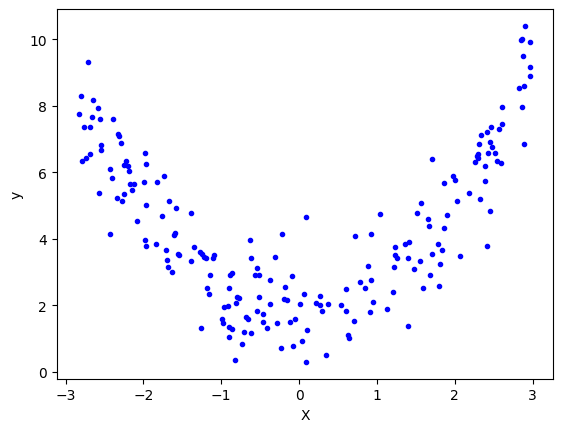

In [12]:
plt.plot(X,y,'b.')
plt.xlabel("X")
plt.ylabel("y")
plt.show()

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state=2)

In [14]:
X_train.shape, X_test.shape

((160, 1), (40, 1))

In [15]:
lr = LinearRegression()

lr.fit(X_train, y_train)

LinearRegression()

In [16]:
y_pred = lr.predict(X_test)

In [17]:
r2_score(y_test, y_pred)

-0.04919557456185775

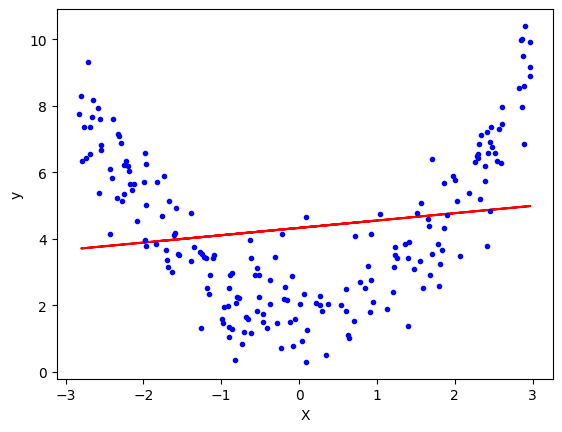

In [18]:
plt.plot(X_train,lr.predict(X_train),color='r')
plt.plot(X, y, "b.")
plt.xlabel("X")
plt.ylabel("y")
plt.show()

In [26]:
poly = PolynomialFeatures(degree = 2, include_bias=True)

X_train_trans = poly.fit_transform(X_train)
X_test_trans = poly.transform(X_test)

In [27]:
print(X_train[0])
print(X_train_trans[0])

[-1.83983581]
[ 1.         -1.83983581  3.3849958 ]


In [28]:
lr = LinearRegression()
lr.fit(X_train_trans,y_train)

LinearRegression()

In [29]:
y_pred = lr.predict(X_test_trans)

In [30]:
r2_score(y_test,y_pred)

0.834541913720432

In [32]:
print(lr.coef_)
print(lr.intercept_)

[[0.         0.01405412 0.81276279]]
[1.80648126]


In [34]:
X_new=np.linspace(-3, 3, 200).reshape(200, 1)
X_new_poly = poly.transform(X_new)
y_new = lr.predict(X_new_poly)

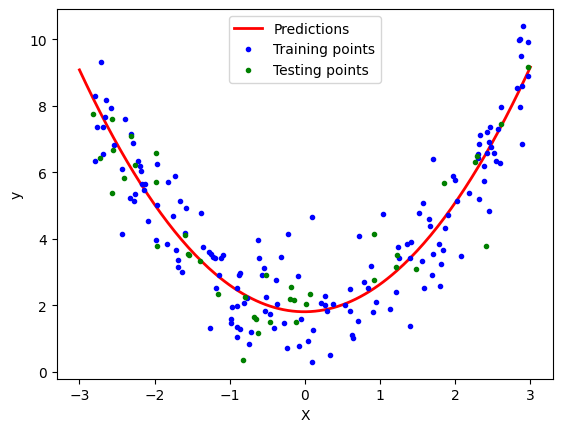

In [35]:
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.plot(X_train, y_train, "b.",label='Training points')
plt.plot(X_test, y_test, "g.",label='Testing points')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [39]:
def polynomial_regression(degree):
    X_new=np.linspace(-3, 3, 100).reshape(100, 1)
    X_new_poly = poly.transform(X_new)

    polybig_features = PolynomialFeatures(degree=degree, include_bias=False)
    std_scaler = StandardScaler()
    lin_reg = LinearRegression()
    polynomial_regression = Pipeline([
            ("poly_features", polybig_features),
            ("std_scaler", std_scaler),
            ("lin_reg", lin_reg),
        ])
    polynomial_regression.fit(X, y)
    y_newbig = polynomial_regression.predict(X_new)
    plt.plot(X_new, y_newbig,'r', label="Degree " + str(degree), linewidth=2)

    plt.plot(X_train, y_train, "b.", linewidth=3)
    plt.plot(X_test, y_test, "g.", linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.axis([-3, 3, 0, 10])
    plt.show()

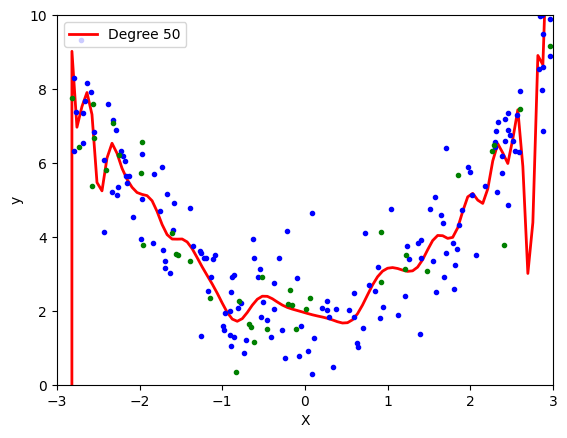

In [41]:
polynomial_regression(50)